<a href="https://colab.research.google.com/github/zaidkhan8241/Stock-Price-Prediction-using-LSTM/blob/main/Stock_Price_Prediction_using_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Stock Price Prediction using LSTM

This notebook demonstrates how to build and train a Long Short-Term Memory (LSTM) neural network model to predict stock prices. We will cover data loading, preprocessing, model definition, training, evaluation, and forecasting future values.

In [2]:
!pip install opendatasets

### 1. Data Loading and Preparation

First, we install and import necessary libraries, then download the stock market dataset from Kaggle. We'll specifically focus on the 'CCOR.csv' file for our predictions.

In [8]:
import opendatasets as od

od.download("https://www.kaggle.com/datasets/jacksoncrow/stock-market-dataset?utm_source=chatgpt.com")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: zaid2006
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/jacksoncrow/stock-market-dataset


100%|██████████| 522M/522M [00:03<00:00, 171MB/s]


After downloading, we load the `CCOR.csv` file into a Pandas DataFrame, setting 'Date' as the index and parsing it as datetime objects. We then extract the 'Close' price column, which will be our target variable for prediction.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
import pandas as pd
df = pd.read_csv("/content/stock-market-dataset/etfs/CCOR.csv",index_col='Date',parse_dates=True)
df.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2017-05-25,25.500000,25.500000,25.028,25.118000,24.179565,26700
2017-05-26,25.190001,25.190001,25.157,25.188000,24.246948,12400
2017-05-30,25.590000,25.590000,25.070,25.070000,24.133360,26900
2017-05-31,25.167000,25.250000,25.163,25.240000,24.297007,11000
2017-06-01,25.700001,25.700001,25.270,25.360001,24.412523,19900


In [22]:
df1=df.reset_index()['Close']

In [30]:
df1.tail()

,Close
713,28.865999
714,28.680000
715,28.684999
716,28.521999
717,28.469999


Visualizing the 'Close' price helps us understand the trend and patterns in the data over time.

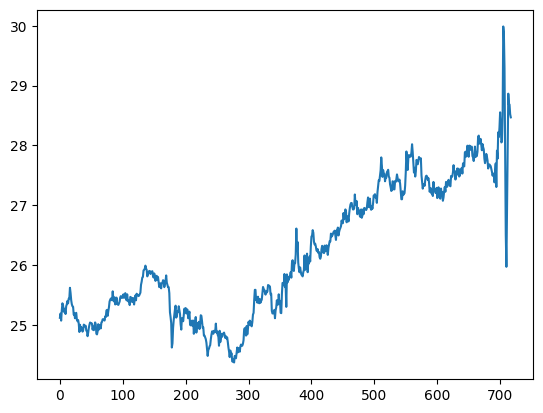

In [24]:
plt.plot(df1)

To prepare the data for the LSTM model, we use `MinMaxScaler` to scale the 'Close' prices between 0 and 1. This normalization is crucial for neural networks to converge efficiently.

In [71]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
# Store the scaled data in a new variable to avoid overwriting the original df (DataFrame)
scaled_data_array = scaler.fit_transform(np.array(df1).reshape(-1,1))

In [26]:
print(df1)

0      25.118000
1      25.188000
2      25.070000
3      25.240000
4      25.360001
         ...    
713    28.865999
714    28.680000
715    28.684999
716    28.521999
717    28.469999
Name: Close, Length: 718, dtype: float64


In [27]:
df.shape

(718, 1)

### 2. Data Splitting

We divide the scaled data into training and testing sets. The training set (65%) will be used to train the LSTM model, and the testing set (35%) will evaluate its performance on unseen data.

In [72]:
split = int(len(scaled_data_array) * 0.65)

train_data = scaled_data_array[0:split, :]
test_data = scaled_data_array[split:len(scaled_data_array), :]

print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

Train data shape: (466, 1)
Test data shape: (252, 1)


### 3. Creating Time-Series Dataset for LSTM

LSTMs require input data in a specific format (samples, time steps, features). The `create_dataset` function transforms our sequential data into this format, where each input `X` consists of `time_step` previous 'Close' prices, and `y` is the next 'Close' price.

In [32]:
import numpy
# convert an array of values into a dataset matrix
def create_dataset(dataset, time_step=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-time_step-1):
		a = dataset[i:(i+time_step), 0]   ###i=0, 0,1,2,3-----99   100
		dataX.append(a)
		dataY.append(dataset[i + time_step, 0])
	return numpy.array(dataX), numpy.array(dataY)

We apply the `create_dataset` function to both our training and testing data. Here, `time_step=100` means the model will look at the previous 100 days' prices to predict the next day's price.

In [73]:
# reshape into X=t,t+1,t+2,t+3 and Y=t+4
time_step = 100
# Use the scaled train_data and test_data
X_train, y_train = create_dataset(train_data, time_step)
X_test, ytest = create_dataset(test_data, time_step)

We then reshape the input `X_train` and `X_test` to fit the LSTM input requirements: `[samples, time steps, features]`.

In [35]:
print(X_train.shape), print(y_train.shape)

(365, 100)
(365,)


(None, None)

In [36]:
print(X_test.shape), print(ytest.shape)

(151, 100)
(151,)


(None, None)

In [37]:
# reshape input to be [samples, time steps, features] which is required for LSTM
X_train =X_train.reshape(X_train.shape[0],X_train.shape[1] , 1)
X_test = X_test.reshape(X_test.shape[0],X_test.shape[1] , 1)

### 4. LSTM Model Definition and Training

Here, we define our LSTM model architecture using TensorFlow/Keras. The model consists of multiple LSTM layers followed by Dense layers. A `sigmoid` activation is used in the final Dense layer to ensure predictions are within the 0-1 scaled range.

In [38]:
### Create the Stacked LSTM model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

In [81]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam

# Define model
model = Sequential([
    Input(shape=(time_step, 1)), # Use Input layer to resolve warning
    LSTM(128, return_sequences=True), # Increased units
    LSTM(64), # Increased units
    Dense(32, activation='relu'), # Increased units
    Dense(1, activation='sigmoid') # Kept sigmoid for scaled output
])
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')

We compile the model with the `Adam` optimizer and `mse` (Mean Squared Error) as the loss function, which is suitable for regression tasks.

In [82]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_16 (LSTM)                  │ (None, 100, 128)       │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,081 (461.25 KB)

 Trainable params: 118,081 (461.25 KB)

 Non-trainable params: 0 (0.00 B)

The model is then trained on the `X_train` and `y_train` data, with validation performed on `X_test` and `ytest` to monitor performance during training over 100 epochs.

In [83]:
model.fit(X_train,y_train,validation_data=(X_test,ytest),epochs=100,batch_size=64,verbose=1)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 460ms/step - loss: 0.0874 - val_loss: 0.0807
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 296ms/step - loss: 0.0363 - val_loss: 0.2469
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 313ms/step - loss: 0.0166 - val_loss: 0.1182
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 301ms/step - loss: 0.0145 - val_loss: 0.1490
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 545ms/step - loss: 0.0129 - val_loss: 0.1720
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 366ms/step - loss: 0.0127 - val_loss: 0.1454
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 299ms/step - loss: 0.0121 - val_loss: 0.1329
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 312ms/step - loss: 0.0120 - val_loss: 0.1459
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 300ms/step - loss: 0.0114 - val_loss: 0.1258
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 298ms/step - loss: 0.0105 - val_loss: 0.1010
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 496ms/step - loss: 0.0083 - val_loss: 0.0455
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 303ms/step - loss: 0.0

### 5. Prediction and Evaluation

After training, we use the model to make predictions on both the training and testing datasets. These predictions are still in the scaled (0-1) format.

In [84]:
import tensorflow as tf

In [85]:
### Lets Do the prediction and check performance metrics
train_predict=model.predict(X_train)
test_predict=model.predict(X_test)

print("Train predictions (before inverse transform) - Min: {:.4f}, Max: {:.4f}".format(np.min(train_predict), np.max(train_predict)))
print("Test predictions (before inverse transform) - Min: {:.4f}, Max: {:.4f}".format(np.min(test_predict), np.max(test_predict)))

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Train predictions (before inverse transform) - Min: 0.0383, Max: 0.4734
Test predictions (before inverse transform) - Min: 0.5806, Max: 0.7247


To interpret the predictions, we inverse transform them back to the original price scale using the `scaler`.

In [86]:
##Transformback to original form
train_predict=scaler.inverse_transform(train_predict)
test_predict=scaler.inverse_transform(test_predict)

print("Train predictions (after inverse transform) - Min: {:.4f}, Max: {:.4f}".format(np.min(train_predict), np.max(train_predict)))
print("Test predictions (after inverse transform) - Min: {:.4f}, Max: {:.4f}".format(np.min(test_predict), np.max(test_predict)))

Train predictions (after inverse transform) - Min: 24.5850, Max: 27.0307
Test predictions (after inverse transform) - Min: 27.6328, Max: 28.4429


We calculate the Root Mean Squared Error (RMSE) for the training data. RMSE measures the average magnitude of the errors between predicted and actual values. Lower RMSE indicates a better fit.

In [87]:
### Calculate RMSE performance metrics
import math
from sklearn.metrics import mean_squared_error

# Inverse transform y_train for RMSE calculation as train_predict is also inverse transformed
y_train_original = scaler.inverse_transform(y_train.reshape(-1, 1))
math.sqrt(mean_squared_error(y_train_original, train_predict))

0.1593793318001776

Similarly, we calculate the RMSE for the test data. This is a critical metric as it shows how well the model performs on data it has not seen before.

In [88]:
### Test Data RMSE
# Inverse transform ytest for RMSE calculation as test_predict is also inverse transformed
ytest_original = scaler.inverse_transform(ytest.reshape(-1, 1))
math.sqrt(mean_squared_error(ytest_original, test_predict))

0.48989416429020216

This plot visualizes the original 'Close' prices alongside the model's predictions for both the training and testing periods. It helps to visually assess how well the model has learned the patterns in the data.

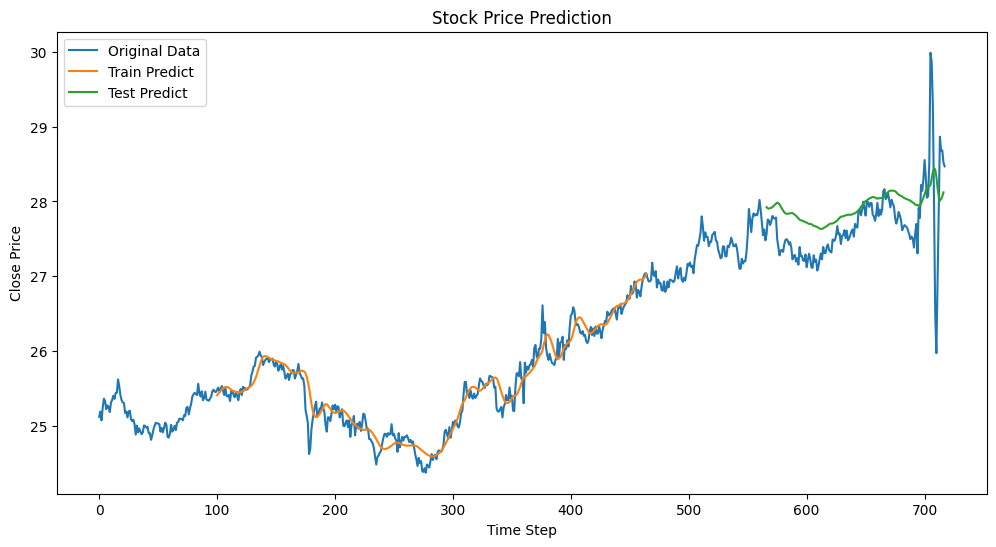

In [96]:
import matplotlib.pyplot as plt

# Shift train predictions for plotting
trainPredictPlot = np.empty_like(scaled_data_array)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[time_step:len(train_predict)+time_step, :] = train_predict

# Shift test predictions for plotting
testPredictPlot = np.empty_like(scaled_data_array)
testPredictPlot[:, :] = np.nan
test_start_index = len(train_data) + time_step + (time_step - 1)

testPredictPlot[len(train_predict)+(time_step*2)+1:len(scaled_data_array)-1, :] = test_predict

# Corrected logic for testPredictPlot placement
test_predict_start_index = len(train_data) + time_step
testPredictPlot[test_predict_start_index:test_predict_start_index + len(test_predict), :] = test_predict

# Plot baseline and predictions
plt.figure(figsize=(12, 6))
plt.plot(scaler.inverse_transform(scaled_data_array), label='Original Data')
plt.plot(trainPredictPlot, label='Train Predict')
plt.plot(testPredictPlot, label='Test Predict')
plt.xlabel('Time Step')
plt.ylabel('Close Price')
plt.title('Stock Price Prediction')
plt.legend()
plt.show()

### 6. Future Price Prediction

This section focuses on predicting future stock prices for the next 40 days. We use an iterative process: the model predicts the next day's price, and this prediction is then fed back into the input sequence to predict the day after, and so on. This creates a chain of future predictions.

### Predicting Future 10 Days

In [99]:
import numpy as np
import tensorflow as tf

# Define a tf.function to wrap the model prediction for consistent input shape
@tf.function(input_signature=[tf.TensorSpec(shape=(1, time_step, 1), dtype=tf.float32)])
def predict_step(input_tensor):
    return model(input_tensor, training=False)

# Initial input for prediction: last 'time_step' values from test_data
last_time_steps = test_data[len(test_data) - time_step:] # Shape (time_step, 1)
x_input_numpy = last_time_steps.reshape(1, time_step, 1) # Reshape to (1, time_step, 1) for the model

lst_output = []
num_future_steps = 40

for i in range(num_future_steps):
    # Predict the next step using the tf.function wrapped prediction
    yhat_tf = predict_step(tf.convert_to_tensor(x_input_numpy, dtype=tf.float32))

    # yhat_tf is a tf.Tensor with shape (1, 1), convert to numpy for list appending and manipulation
    yhat_numpy = yhat_tf.numpy()

    # Append the scalar prediction to our list
    lst_output.append(yhat_numpy[0][0])

    # Update the input sequence for the next prediction using numpy operations
    next_input_sequence = x_input_numpy[0, 1:, :] # Get all but the first element, shape (time_step-1, 1)

    # Stack the new prediction (reshaped to (1,1))
    next_input_sequence = np.vstack((next_input_sequence, yhat_numpy[0].reshape(1, 1))) # Shape (time_step, 1)

    # Reshape for the next model input
    x_input_numpy = next_input_sequence.reshape(1, time_step, 1)

print("Future 10-day scaled predictions:", lst_output)

Future 10-day scaled predictions: [np.float32(0.68550014), np.float32(0.69099444), np.float32(0.6951127), np.float32(0.6978876), np.float32(0.69945884), np.float32(0.70003814), np.float32(0.6998645), np.float32(0.69917625), np.float32(0.69819295), np.float32(0.69710255), np.float32(0.69605446), np.float32(0.69515544), np.float32(0.6944719), np.float32(0.6940324), np.float32(0.6938364), np.float32(0.6938599), np.float32(0.69406503), np.float32(0.69440496), np.float32(0.69483244), np.float32(0.69530267), np.float32(0.6957775), np.float32(0.6962272), np.float32(0.69663125), np.float32(0.6969776), np.float32(0.6972612), np.float32(0.697484), np.float32(0.6976516), np.float32(0.6977726), np.float32(0.69785756), np.float32(0.6979169), np.float32(0.6979599), np.float32(0.69799465), np.float32(0.69802797), np.float32(0.69806427), np.float32(0.698106), np.float32(0.6981547), np.float32(0.6982104), np.float32(0.6982718), np.float32(0.6983376), np.float32(0.69840616)]


The future predictions (which were generated in scaled form) are now inverse-transformed back to their original price scale for easy interpretation. We then print these 40-day future predictions.

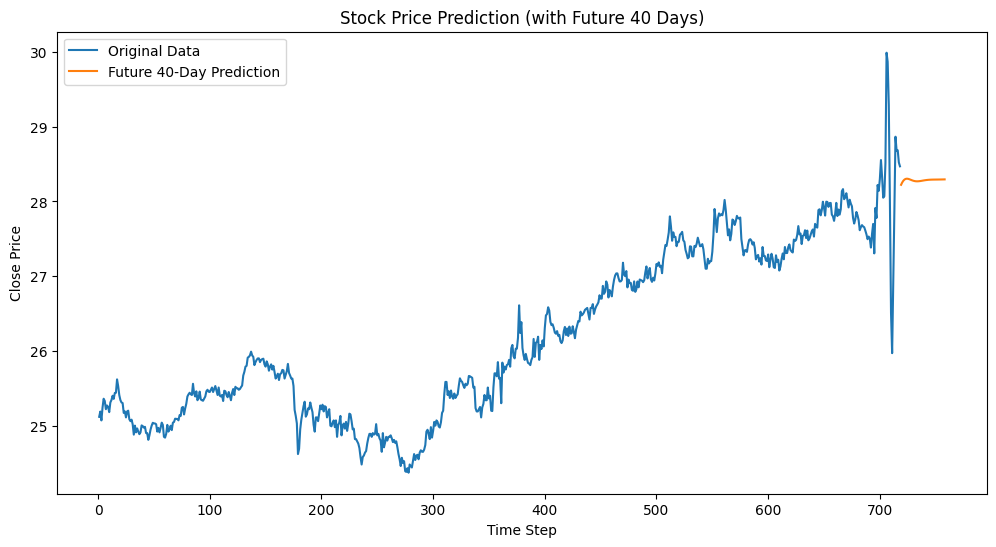

In [101]:
day_new = np.arange(1, len(scaled_data_array) + 1)
day_pred = np.arange(len(scaled_data_array) + 1, len(scaled_data_array) + num_future_steps + 1)

plt.figure(figsize=(12, 6))
plt.plot(day_new, scaler.inverse_transform(scaled_data_array), label='Original Data')
plt.plot(day_pred, scaler.inverse_transform(np.array(lst_output).reshape(-1, 1)), label='Future 40-Day Prediction')
plt.xlabel('Time Step')
plt.ylabel('Close Price')
plt.title('Stock Price Prediction (with Future 40 Days)')
plt.legend()
plt.show()

### Inverse-Transformed Future Predictions

In [102]:
future_predictions_original_scale = scaler.inverse_transform(np.array(lst_output).reshape(-1, 1))
for i, pred in enumerate(future_predictions_original_scale):
    print(f"Day {i+1}: {pred[0]:.4f}")

Day 1: 28.2225
Day 2: 28.2534
Day 3: 28.2765
Day 4: 28.2921
Day 5: 28.3010
Day 6: 28.3042
Day 7: 28.3032
Day 8: 28.2994
Day 9: 28.2938
Day 10: 28.2877
Day 11: 28.2818
Day 12: 28.2768
Day 13: 28.2729
Day 14: 28.2705
Day 15: 28.2694
Day 16: 28.2695
Day 17: 28.2706
Day 18: 28.2726
Day 19: 28.2750
Day 20: 28.2776
Day 21: 28.2803
Day 22: 28.2828
Day 23: 28.2851
Day 24: 28.2870
Day 25: 28.2886
Day 26: 28.2899
Day 27: 28.2908
Day 28: 28.2915
Day 29: 28.2920
Day 30: 28.2923
Day 31: 28.2925
Day 32: 28.2927
Day 33: 28.2929
Day 34: 28.2931
Day 35: 28.2934
Day 36: 28.2936
Day 37: 28.2939
Day 38: 28.2943
Day 39: 28.2947
Day 40: 28.2950


Finally, we plot the original historical data along with the projected 40-day future predictions. This provides a visual representation of the model's forecast.